# Uno sguardo sull'andamento dell'istruzione femminile in Europa
L'European Institute for Gender Equality ha pubblicato un database contenente degli indicatori utili per quantificare la parità di genere in Europa: il Gender Statistics Database. 
In questa esercitazione esploreremo un dataset appartenente a questo database. L'indicatore prescelto è il "At least upper secondary educational attainment, age group 25-64 by sex" (https://eige.europa.eu/gender-statistics/dgs/indicator/ta_eductrain_educ__tps00065/datatable?age=Y25-64&isced11=ED3-8&unit=PC&col=time&row=geo&colg=sex). Questo indicatore rappresenta la percentuale di popolazione con un'età compresa tra il 25 e i 64 anni che ha conseguito un diploma di istruzione compreso tra i livelli internazionali di 3 e 8. 
La Classificazione internazionale standard dell'istruzione raggrupopa i corsi di studio nei seguenti livelli: 

|Livello|Descrizione|Caratteristiche principali|
|-----|----|----|
|0|Istruzione prescolastica (01 asilo nido)|Istruzione mirata a sostenere lo sviluppo iniziale in preparazione alla partecipazione nella scuola e nella società. Per bambini al di sotto dei 3 anni|
|0|Istruzione prescolastica (02 scuola dell'infanzia)|Istruzione mirata a sostenere lo sviluppo iniziale in preparazione alla partecipazione nella scuola e nella società. Per bambini dai 3 anni all'inizio dell'istruzione primaria|
|1|Istruzione primaria|Programmi tipicamente mirati a fornire agli studenti le competenze fondamentali in lettura, scrittura e matematica, e a stabilire una solida base di apprendimento generale|
|2|Istruzione secondaria inferiore|Primo stadio di istruzione secondaria, che si basa sull'istruzione primaria, tipicamente con un curriculum più orientato alle materie.
|3|Istruzione secondaria superiore|Secondo/ultimo stadio di istruzione secondaria che prepara all'istruzione terziaria e/o fornisce competenze utili all'inserimento nel mercato del lavoro. Solitamente con una vasta gamma di materie tra cui scegliere.|
|4|Istruzione post-secondaria non-terziaria|Programmi che forniscono esperienze di apprendimento che si basano sull'istruzione secondaria e preparano al mercato del lavoro. Il contenuto è più esteso rispetto alla secondaria ma non così complesso quanto l'istruzione terziaria.|
|5|Istruzione terziaria a ciclo breve|Primi programmi terziari brevi tipicamente pratici, specifici all'occupazione e preparativi per l'ingresso nel mercato del lavoro. Questi programmi possono anche fornire un ingresso ad altri programmi terziari.|
|6|Istruzione superiore: Bachelor o equivalenti (Laurea triennale)|Programmi mirati a fornire conoscenze, qualifiche e competenze professionali e/o accademiche di livello intermedio, che portano a una prima laurea terziaria a un certificato equivalente.|
|7|Istruzione superiore: Master o equivalenti (Laurea magistrale)|Programmi mirati a fornire conoscenze, qualifiche e competenze professionali e/o accademiche di livello avanzato, che portano a una seconda laurea terziaria o a un certificato equivalente.|
|8|Istruzione superiore: Dottorale o equivalenti (Dottorato)|Programmi mirati principalmente al conseguimento di un certificato di ricerca avanzato, solitamente conclusi con la consegna e la difesa di una dissertazione considerevole basata su ricerche originali, di qualità tale da essere pubblicabile|

I livelli di istruzione dal 3 e l'8 comprendono quindi l'istruzione che va dal diplome di istruzione superiore al dottorato. 



## Creo l'ambiente

In [109]:
#creo l'ambiente 
#conda create --name esercitazione
#conda activate esercitazione

## Installo le librerie

In [106]:
#installazione delle librerie (se necessario)
#conda install numpy
#conda install pandas
#conda install geopandas
#conda install matplotlib
#conda install highlight_text

In [1]:
#import delle librerie
import numpy as np
import pandas as pd
import geopandas as gpd

import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import matplotlib.patches as patches
from  highlight_text import fig_text

## Carico i dati

In [2]:
#leggiamo il dataset 
path_df = "/home/jovyan/work/data/esercitazione_def.CSV"
df = pd.read_csv(path_df, sep=";")  

In [14]:
#dati per mappe
#importo shapefile per mappa
#https://www.naturalearthdata.com/downloads/110m-cultural-vectors/
path_world = "/home/jovyan/work/data/ne_110m_admin_0_countries/ne_110m_admin_0_countries.shp" 
world = gpd.read_file(path_world)

In [15]:
# filtro per europa e turchia
europe = world.query("CONTINENT=='Europe' or NAME =='Turkey' or NAME=='Cyprus' or NAME=='Malta' " )

## Data exploration

In [16]:
df.head()

,country,gender,key,2013_up_sec_edu_perc,2014_up_sec_edu_perc,2015_up_sec_edu_perc,2016_up_sec_edu_perc,2017_up_sec_edu_perc,2018_up_sec_edu_perc,2019_up_sec_edu_perc,...,2015_up_sec_edu_tot,2016_up_sec_edu_tot,2017_up_sec_edu_tot,2018_up_sec_edu_tot,2019_up_sec_edu_tot,2020_up_sec_edu_tot,2021_up_sec_edu_tot,2022_up_sec_edu_tot,2023_up_sec_edu_tot,2024_up_sec_edu_tot
0,Austria,Females,Austria_Females,0.79,0.80,0.81,0.81,0.82,0.82,0.83,...,1926075.0,1949652.0,1989602.0,2008203.0,2038806.0,2058686.0,2077768,2085886,2112761,2141989
1,Austria,Males,Austria_Males,0.87,0.88,0.89,0.88,0.88,0.89,0.88,...,2109497.0,2131097.0,2155724.0,2182395.0,2189185.0,2197408.0,2210624,2216376,2239331,2232681
2,Austria,Total,Austria_Total,0.83,0.84,0.85,0.85,0.85,0.85,0.86,...,4031146.0,4080628.0,4145124.0,4190312.0,4230144.0,4258220.0,4285471,4299187,4351702,4374352
3,Belgium,Females,Belgium_Females,0.74,0.75,0.76,0.76,0.78,0.79,0.80,...,2255446.0,2267881.0,2328660.0,2377138.0,2417403.0,2456840.0,2498888,2527429,2547063,2572854
4,Belgium,Males,Belgium_Males,0.72,0.72,0.74,0.74,0.76,0.77,0.77,...,2205133.0,2238504.0,2290319.0,2341463.0,2342598.0,2384220.0,2452460,2490698,2495436,2522376


In [17]:
df.columns

Index(['country', 'gender', 'key', '2013_up_sec_edu_perc',
       '2014_up_sec_edu_perc', '2015_up_sec_edu_perc', '2016_up_sec_edu_perc',
       '2017_up_sec_edu_perc', '2018_up_sec_edu_perc', '2019_up_sec_edu_perc',
       '2020_up_sec_edu_perc', '2021_up_sec_edu_perc', '2022_up_sec_edu_perc',
       '2023_up_sec_edu_perc', '2024_up_sec_edu_perc', '2013_pop', '2014_pop',
       '2015_pop', '2016_pop', '2017_pop', '2018_pop', '2019_pop', '2020_pop',
       '2021_pop', '2022_pop', '2023_pop', '2024_pop', '2013_up_sec_edu_tot',
       '2014_up_sec_edu_tot', '2015_up_sec_edu_tot', '2016_up_sec_edu_tot',
       '2017_up_sec_edu_tot', '2018_up_sec_edu_tot', '2019_up_sec_edu_tot',
       '2020_up_sec_edu_tot', '2021_up_sec_edu_tot', '2022_up_sec_edu_tot',
       '2023_up_sec_edu_tot', '2024_up_sec_edu_tot'],
      dtype='object')

In [18]:
#quali nazioni sono presenti?
print(df.sort_values(by='country')['country'].unique())

['Austria' 'Belgium' 'BosniaandHerzegovina' 'Bulgaria' 'Croatia' 'Cyprus'
 'Czechia' 'Denmark' 'Estonia' 'Euroarea(20countries)'
 'EuropeanUnion-27countries(from2020)' 'Finland' 'France' 'Germany'
 'Greece' 'Hungary' 'Iceland' 'Ireland' 'Italy' 'Latvia' 'Lithuania'
 'Luxembourg' 'Malta' 'Montenegro' 'Netherlands' 'NorthMacedonia' 'Norway'
 'Poland' 'Portugal' 'Romania' 'Serbia' 'Slovakia' 'Slovenia' 'Spain'
 'Sweden' 'Switzerland' 'Turkiye' 'UnitedKingdom']


In [19]:
print(europe.sort_values(by='NAME')['NAME'].unique())

['Albania' 'Austria' 'Belarus' 'Belgium' 'Bosnia and Herz.' 'Bulgaria'
 'Croatia' 'Cyprus' 'Czechia' 'Denmark' 'Estonia' 'Finland' 'France'
 'Germany' 'Greece' 'Hungary' 'Iceland' 'Ireland' 'Italy' 'Kosovo'
 'Latvia' 'Lithuania' 'Luxembourg' 'Moldova' 'Montenegro' 'Netherlands'
 'North Macedonia' 'Norway' 'Poland' 'Portugal' 'Romania' 'Russia'
 'Serbia' 'Slovakia' 'Slovenia' 'Spain' 'Sweden' 'Switzerland' 'Turkey'
 'Ukraine' 'United Kingdom']


## Data Cleaning

In [43]:
#alcune nazioni necessitano di pulizia sui nomi
nomi_paesi = {
    "BosniaandHerzegovina": "Bosnia and Herz.",
    "NorthMacedonia": "North Macedonia",
    "Turkiye": "Turkey",
    "UnitedKingdom": "United Kingdom"
}

df["country"] = df["country"].replace(nomi_paesi)

## Data Preparation
Creo delle colonne che serviranno in seguito per l'analisi. Preparo i dataset divisi per donne e uomini

In [46]:
#differenza tra 2013 e 2023
df['variazione_pp'] = (df['2023_up_sec_edu_perc'] - df['2013_up_sec_edu_perc']) * 100 
df[['country', 'gender', '2013_up_sec_edu_perc', '2023_up_sec_edu_perc', 'variazione_pp']]

,country,gender,2013_up_sec_edu_perc,2023_up_sec_edu_perc,variazione_pp
0,Austria,Females,0.79,0.84,5.0
1,Austria,Males,0.87,0.88,1.0
2,Austria,Total,0.83,0.86,3.0
3,Belgium,Females,0.74,0.83,9.0
4,Belgium,Males,0.72,0.81,9.0
...,...,...,...,...,...
109,Turkey,Males,0.38,0.51,13.0
110,Turkey,Total,0.32,0.46,14.0
111,United Kingdom,Females,0.77,NaN,NaN
112,United Kingdom,Males,0.80,NaN,NaN


In [47]:
#creo dataset per uomini e donne
donne = df[df["gender"] == "Females"].copy()
uomini = df[df["gender"] == "Males"].copy()

## Analisi
Di seguito sono riportati alcuni esempi di analisi dati.

## Confronto tra uomini e donne

In [51]:
confronto = donne[
    ["country", "2023_up_sec_edu_perc"]
].merge(
    uomini[["country", "2023_up_sec_edu_perc"]],
    on="country",
    suffixes=("_donne", "_uomini")
)

confronto["gap_pp"] = (
    confronto["2023_up_sec_edu_perc_donne"]
    - confronto["2023_up_sec_edu_perc_uomini"]
) * 100

confronto.sort_values("gap_pp")

,country,2023_up_sec_edu_perc_donne,2023_up_sec_edu_perc_uomini,gap_pp
2,Bosnia and Herz.,0.75,0.87,-12.0
36,Turkey,0.41,0.51,-10.0
0,Austria,0.84,0.88,-4.0
29,Romania,0.79,0.82,-3.0
30,Serbia,0.83,0.85,-2.0
4,Croatia,0.88,0.90,-2.0
35,Switzerland,0.85,0.87,-2.0
32,Slovenia,0.88,0.89,-1.0
15,Hungary,0.87,0.88,-1.0
6,Czechia,0.94,0.95,-1.0


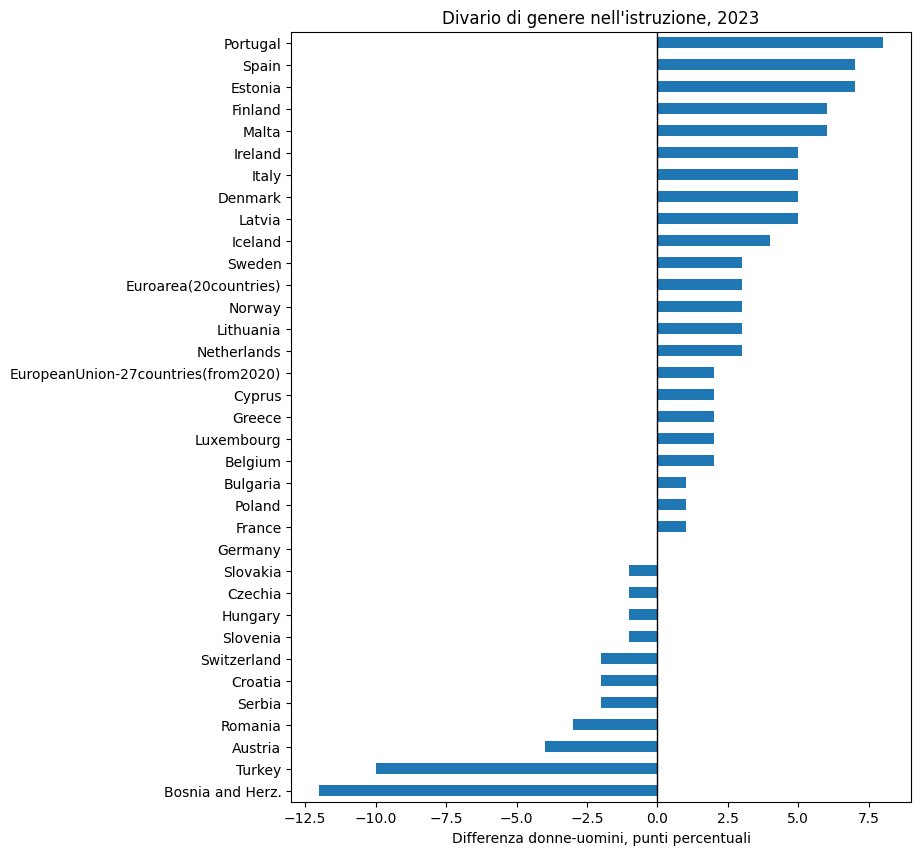

In [49]:
confronto_paesi = (
    confronto
    .dropna()
    .sort_values("gap_pp")
)

confronto_paesi.plot.barh(
    x="country",
    y="gap_pp",
    figsize=(8, 10),
    legend=False
)

plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Differenza donne-uomini, punti percentuali")
plt.ylabel("")
plt.title("Divario di genere nell'istruzione, 2023")
plt.show()

## Costruiamo un ranking per il 2023

In [52]:
# Colonne che utilizzeremo nell'analisi
colonna_paese = "country"
colonna_genere = "gender"
colonna_valore = "2023_up_sec_edu_perc"

# Seleziono i dati relativi alle donne
donne_2023 = df[
    df[colonna_genere] == "Females"
][[colonna_paese, colonna_valore]].copy()

# Seleziono i dati relativi agli uomini
uomini_2023 = df[
    df[colonna_genere] == "Males"
][[colonna_paese, colonna_valore]].copy()

# Rinomino le colonne per renderle più comprensibili
donne_2023 = donne_2023.rename(
    columns={colonna_valore: "percentuale_donne"}
)

uomini_2023 = uomini_2023.rename(
    columns={colonna_valore: "percentuale_uomini"}
)

In [53]:
display(donne_2023.head())
display(uomini_2023.head())

,country,percentuale_donne
0,Austria,0.84
3,Belgium,0.83
6,Bosnia and Herz.,0.75
9,Bulgaria,0.86
12,Croatia,0.88


,country,percentuale_uomini
1,Austria,0.88
4,Belgium,0.81
7,Bosnia and Herz.,0.87
10,Bulgaria,0.85
13,Croatia,0.90


In [54]:
#togliamo la media europea
nome_aggregato_ue = "EuropeanUnion-27countries(from2020)"

donne_paesi_2023 = donne_2023[
    donne_2023[colonna_paese] != nome_aggregato_ue
].copy()

In [55]:
donne_paesi_2023["posizione"] = (
    donne_paesi_2023["percentuale_donne"]
    .rank(
        ascending=False,
        method="min"
    )
)

In [56]:
#visualizziamo il ranking 
ranking_donne_2023 = (
    donne_paesi_2023
    .sort_values(
        by=["posizione", colonna_paese]
    )
    .reset_index(drop=True)
)

ranking_donne_2023.head(10)

,country,percentuale_donne,posizione
0,Lithuania,0.96,1.0
1,Poland,0.95,2.0
2,Czechia,0.94,3.0
3,Latvia,0.94,3.0
4,Estonia,0.93,5.0
5,Slovakia,0.93,5.0
6,Finland,0.92,7.0
7,Ireland,0.91,8.0
8,Sweden,0.90,9.0
9,Croatia,0.88,10.0


## Confrontiamo i valori con l'aggregato UE

In [57]:
aggregato_ue_2023 = donne_2023.loc[
    donne_2023[colonna_paese] == nome_aggregato_ue,
    "percentuale_donne"
].squeeze()

print(
    "Aggregato UE relativo alle donne nel 2023:",
    aggregato_ue_2023
)

Aggregato UE relativo alle donne nel 2023: 0.81


In [67]:
# Creiamo una colonna che indichi la posizione
# di ogni paese rispetto al valore UE

donne_paesi_2023["rispetto_ue"] = (
    donne_paesi_2023["percentuale_donne"]
    .apply(
        lambda valore: (
            "NA"
            if pd.isna(valore)
            else "Sopra l'aggregato UE"
            if valore > aggregato_ue_2023
            else "Sotto l'aggregato UE"
            if valore < aggregato_ue_2023
            else "Uguale all'aggregato UE"
        )
    )
)

In [68]:
#calcoliamo la distanza dall'aggreagato UE
donne_paesi_2023["differenza_ue_pp"] = (
    donne_paesi_2023["percentuale_donne"]
    - aggregato_ue_2023
) * 100

donne_paesi_2023[
    [
        colonna_paese,
        "percentuale_donne",
        "differenza_ue_pp",
        "rispetto_ue"
    ]
].sort_values(
    "differenza_ue_pp",
    ascending=False
)

,country,percentuale_donne,differenza_ue_pp,rispetto_ue
60,Lithuania,0.96,15.0,Sopra l'aggregato UE
81,Poland,0.95,14.0,Sopra l'aggregato UE
18,Czechia,0.94,13.0,Sopra l'aggregato UE
57,Latvia,0.94,13.0,Sopra l'aggregato UE
93,Slovakia,0.93,12.0,Sopra l'aggregato UE
24,Estonia,0.93,12.0,Sopra l'aggregato UE
33,Finland,0.92,11.0,Sopra l'aggregato UE
51,Ireland,0.91,10.0,Sopra l'aggregato UE
102,Sweden,0.90,9.0,Sopra l'aggregato UE
12,Croatia,0.88,7.0,Sopra l'aggregato UE


In [70]:
#quanti sono sopra e quanti sono sotto?
donne_paesi_2023["rispetto_ue"].value_counts()

rispetto_ue
Sopra l'aggregato UE    26
Sotto l'aggregato UE     8
NA                       3
Name: count, dtype: int64

## Calcolo del gap tra donne e uomini

In [71]:
confronto_2023 = donne_2023.merge(
    uomini_2023,
    on=colonna_paese,
    how="inner"
)

confronto_2023.head()

,country,percentuale_donne,percentuale_uomini
0,Austria,0.84,0.88
1,Belgium,0.83,0.81
2,Bosnia and Herz.,0.75,0.87
3,Bulgaria,0.86,0.85
4,Croatia,0.88,0.90


In [74]:
#togliamo l'aggregato
confronto_paesi_2023 = confronto_2023[
    confronto_2023[colonna_paese] != nome_aggregato_ue
].copy()

In [76]:
confronto_paesi_2023["gap_donne_uomini_pp"] = (
    confronto_paesi_2023["percentuale_donne"]
    - confronto_paesi_2023["percentuale_uomini"]
) * 100

## 5 paesi con un gap di istruzione più favorevole per le donne

In [77]:
confronto_paesi_2023.nlargest(
    5,
    "gap_donne_uomini_pp"
)[
    [
        colonna_paese,
        "gap_donne_uomini_pp"
    ]
]

,country,gap_donne_uomini_pp
28,Portugal,8.0
8,Estonia,7.0
33,Spain,7.0
11,Finland,6.0
22,Malta,6.0


## 5 paesi con gap più basso per le donne

In [78]:
confronto_paesi_2023.nsmallest(
    5,
    "gap_donne_uomini_pp"
)[
    [
        colonna_paese,
        "gap_donne_uomini_pp"
    ]
]

,country,gap_donne_uomini_pp
2,Bosnia and Herz.,-12.0
36,Turkey,-10.0
0,Austria,-4.0
29,Romania,-3.0
4,Croatia,-2.0


## Rappresentazione su mappa

In [83]:
mappa_gap_2023 = europe.merge(
    confronto_paesi_2023[
        [
            colonna_paese,
            "percentuale_donne",
            "percentuale_uomini",
            "gap_donne_uomini_pp"
        ]
    ],
    left_on="ADMIN",
    right_on=colonna_paese,
    how="left"
)

In [84]:
mappa_gap_2023[
    [
        "ADMIN",
        "percentuale_donne",
        "percentuale_uomini",
        "gap_donne_uomini_pp"
    ]
].head()

,ADMIN,percentuale_donne,percentuale_uomini,gap_donne_uomini_pp
0,Russia,NaN,NaN,NaN
1,Norway,0.85,0.82,3.0
2,France,0.84,0.83,1.0
3,Sweden,0.90,0.87,3.0
4,Belarus,NaN,NaN,NaN


In [86]:
#dove non ho trovato valori 
mappa_gap_2023.loc[
    mappa_gap_2023["gap_donne_uomini_pp"].isna(),
    "ADMIN"
].sort_values().tolist()

['Albania',
 'Belarus',
 'Bosnia and Herzegovina',
 'Kosovo',
 'Moldova',
 'Montenegro',
 'North Macedonia',
 'Republic of Serbia',
 'Russia',
 'Ukraine',
 'United Kingdom']

In [87]:
limite = (
    mappa_gap_2023["gap_donne_uomini_pp"]
    .abs()
    .max()
)

print("Limite della scala:", limite)

Limite della scala: 10.000000000000004


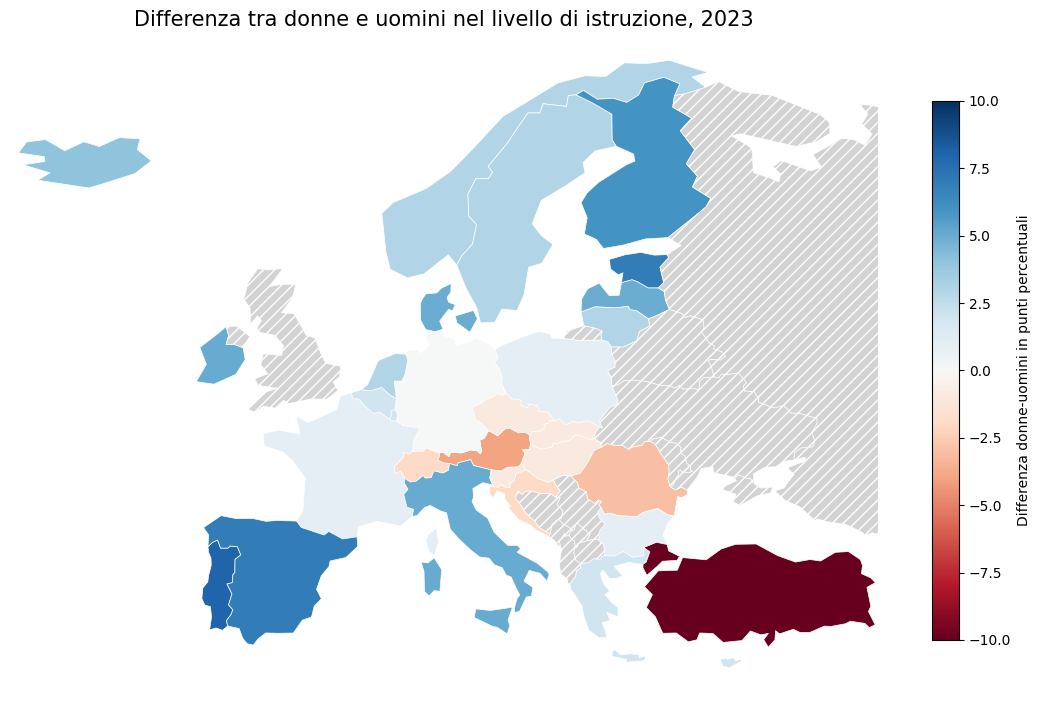

In [88]:
fig, ax = plt.subplots(
    figsize=(14, 10)
)

mappa_gap_2023.plot(
    column="gap_donne_uomini_pp",
    cmap="RdBu",
    vmin=-limite,
    vmax=limite,
    linewidth=0.5,
    edgecolor="white",
    legend=True,
    missing_kwds={
        "color": "lightgrey",
        "edgecolor": "white",
        "hatch": "///",
        "label": "Dato non disponibile"
    },
    legend_kwds={
        "label": (
            "Differenza donne-uomini "
            "in punti percentuali"
        ),
        "shrink": 0.7
    },
    ax=ax
)

ax.set_title(
    "Differenza tra donne e uomini nel livello di istruzione, 2023",
    fontsize=15,
    pad=15
)

ax.set_subtitle = None

ax.set_xlim(-25, 45)
ax.set_ylim(33, 72)

ax.axis("off")

plt.show()